In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv("CarPrice_Assignment.csv")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print(df.isnull().sum())

Number of rows: 205
Number of columns: 26
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64


In [5]:
print(df.info())
print("Number of duplicate rows:", df.duplicated().sum())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    str    
 3   fueltype          205 non-null    str    
 4   aspiration        205 non-null    str    
 5   doornumber        205 non-null    str    
 6   carbody           205 non-null    str    
 7   drivewheel        205 non-null    str    
 8   enginelocation    205 non-null    str    
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    str    
 15  cylindernumber    205 non-null    str    
 16  enginesize        205 non-null    int64  
 17  fuelsyst

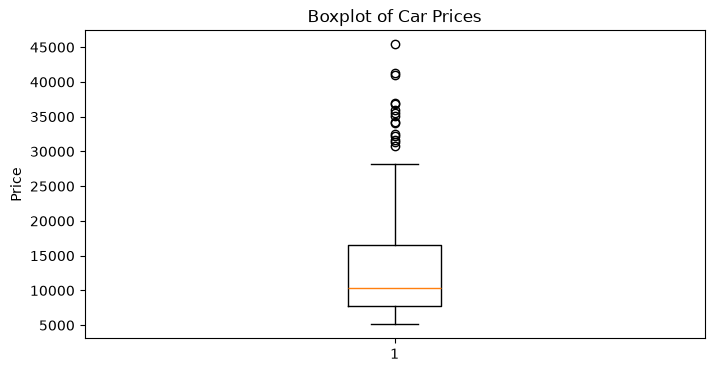

In [6]:
#to detect outliers
plt.figure(figsize=(8, 4))
plt.boxplot(df['price'])
plt.ylabel("Price")
plt.title("Boxplot of Car Prices")

plt.show()

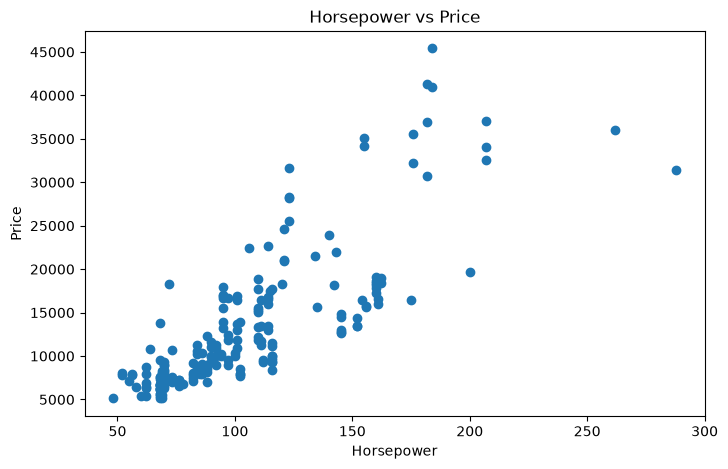

In [7]:
plt.figure(figsize=(8, 5))
plt.scatter(df['horsepower'], df['price'])
plt.xlabel("Horsepower")
plt.ylabel("Price")
plt.title("Horsepower vs Price")

plt.show()

In [8]:
features = [
    'wheelbase',
    'carlength',
    'carwidth',
    'carheight',
    'curbweight',
    'enginesize',
    'boreratio',
    'stroke',
    'compressionratio',
    'horsepower',
    'peakrpm',
    'citympg',
    'highwaympg'
]

X = df[features].values
y = df['price'].values

In [9]:
np.random.seed(42)

indices = np.random.permutation(len(X))

train_size = int(0.8 * len(X))

train_indices = indices[:train_size]
test_indices = indices[train_size:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 164
Testing samples: 41


In [10]:
mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

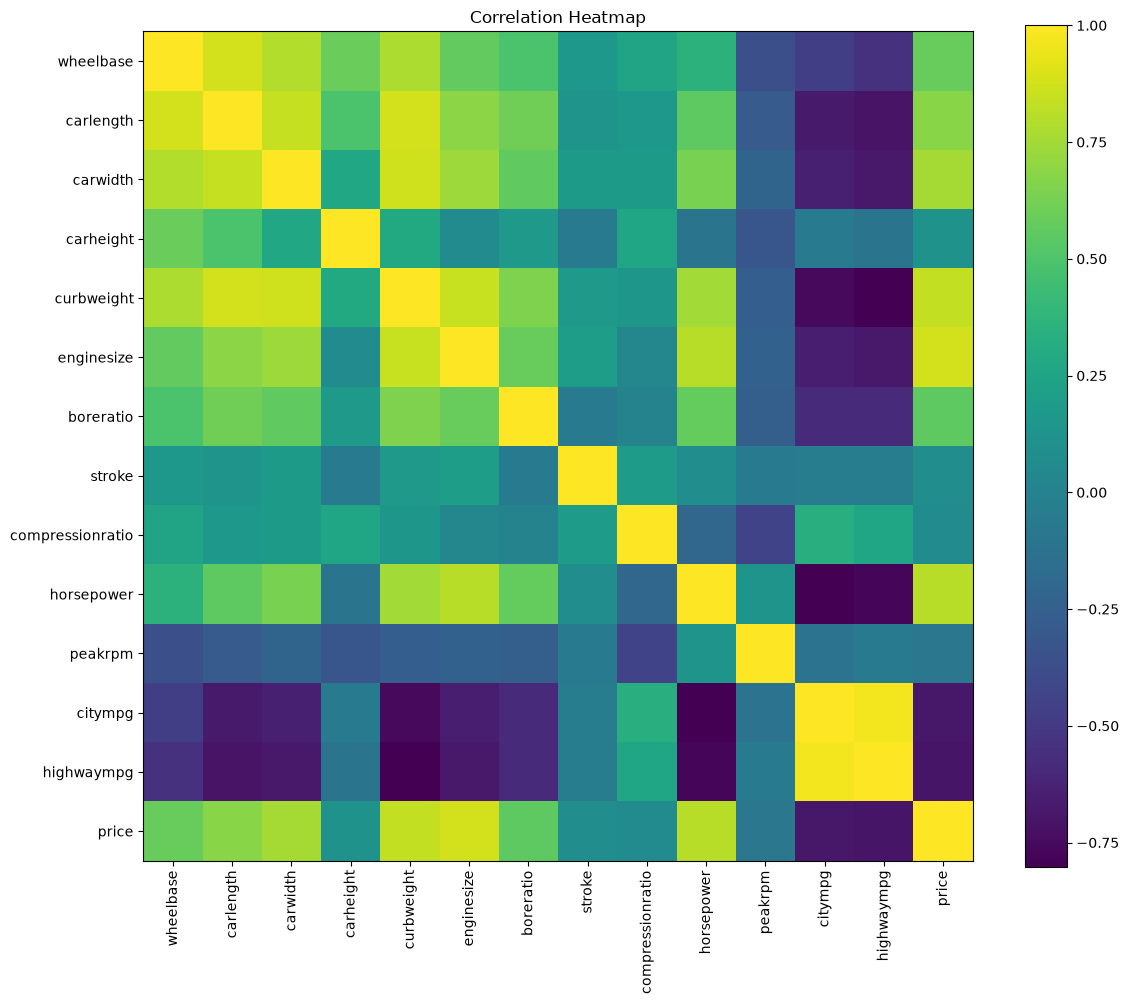

In [20]:
correlation = df[features + ['price']].corr()

plt.figure(figsize=(12, 10))
plt.imshow(correlation, interpolation='nearest')
plt.colorbar()

plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=90)
plt.yticks(range(len(correlation.columns)), correlation.columns)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [11]:
def compute_cost(X, y, w, b):
    m = X.shape[0]
    cost = 0

    for i in range(m):
        f = np.dot(X[i], w) + b
        error = f - y[i]
        cost += error ** 2

    cost = cost / (2 * m)

    return cost

In [12]:
def gradient_descent(X, y, w, b, alpha, iterations):
    m = X.shape[0]
    cost_history = []

    for i in range(iterations):

        dj_dw = np.zeros(len(w))
        dj_db = 0

        for j in range(m):

            f = np.dot(X[j], w) + b
            error = f - y[j]

            for k in range(len(w)):
                dj_dw[k] += error * X[j][k]

            dj_db += error

        for k in range(len(w)):
            dj_dw[k] = dj_dw[k] / m

        dj_db = dj_db / m

        for k in range(len(w)):
            w[k] = w[k] - alpha * dj_dw[k]

        b = b - alpha * dj_db

        cost_history.append(compute_cost(X, y, w, b))

    return w, b, cost_history

In [21]:
alphas = [0.001, 0.005, 0.01, 0.05]

alpha_costs = []

for alpha_value in alphas:

    w_temp = np.zeros(X_train.shape[1])
    b_temp = 0

    w_temp, b_temp, cost_temp = gradient_descent(
        X_train,
        y_train,
        w_temp,
        b_temp,
        alpha_value,
        5000
    )

    alpha_costs.append(cost_temp[-1])

for i in range(len(alphas)):
    print("Alpha:", alphas[i], "Final Cost:", alpha_costs[i])

Alpha: 0.001 Final Cost: 4473093.437215751
Alpha: 0.005 Final Cost: 4294532.572570826
Alpha: 0.01 Final Cost: 4258421.130785478
Alpha: 0.05 Final Cost: 4235901.292752995


In [22]:
best_alpha_index = np.argmin(alpha_costs)
best_alpha = alphas[best_alpha_index]

print("Selected Alpha:", best_alpha)

Selected Alpha: 0.05


In [23]:
iteration_values = [1000, 3000, 5000, 10000]

iteration_costs = []

for iteration_value in iteration_values:

    w_temp = np.zeros(X_train.shape[1])
    b_temp = 0

    w_temp, b_temp, cost_temp = gradient_descent(
        X_train,
        y_train,
        w_temp,
        b_temp,
        best_alpha,
        iteration_value
    )

    iteration_costs.append(cost_temp[-1])

for i in range(len(iteration_values)):
    print("Iterations:", iteration_values[i], 
          "Final Cost:", iteration_costs[i])

Iterations: 1000 Final Cost: 4258405.107673607
Iterations: 3000 Final Cost: 4236439.516548655
Iterations: 5000 Final Cost: 4235901.292752995
Iterations: 10000 Final Cost: 4235887.720467503


In [24]:
best_iteration_index = np.argmin(iteration_costs)
best_iterations = iteration_values[best_iteration_index]

print("Selected Iterations:", best_iterations)

Selected Iterations: 10000


In [25]:
w = np.zeros(X_train.shape[1])
b = 0

alpha = best_alpha
iterations = best_iterations

print("Selected Alpha:", alpha)
print("Selected Iterations:", iterations)

print("Number of weights:", len(w))
print("Initial bias:", b)

w, b, cost_history = gradient_descent(
    X_train,
    y_train,
    w,
    b,
    alpha,
    iterations
)

print("Training complete")

Selected Alpha: 0.05
Selected Iterations: 10000
Number of weights: 13
Initial bias: 0
Training complete


In [14]:
w, b, cost_history = gradient_descent(
    X_train,
    y_train,
    w,
    b,
    alpha,
    iterations
)

print("Training complete")

Training complete


In [27]:
y_train_pred = np.zeros(len(X_train))

for i in range(len(X_train)):
    y_train_pred[i] = np.dot(X_train[i], w) + b

y_test_pred = np.zeros(len(X_test))

for i in range(len(X_test)):
    y_test_pred[i] = np.dot(X_test[i], w) + b

In [28]:
train_mae = np.mean(np.abs(y_train - y_train_pred))
train_mse = np.mean((y_train - y_train_pred) ** 2)
train_rmse = np.sqrt(train_mse)

train_ss_res = np.sum((y_train - y_train_pred) ** 2)
train_ss_tot = np.sum((y_train - np.mean(y_train)) ** 2)

train_r2 = 1 - (train_ss_res / train_ss_tot)


test_mae = np.mean(np.abs(y_test - y_test_pred))
test_mse = np.mean((y_test - y_test_pred) ** 2)
test_rmse = np.sqrt(test_mse)

test_ss_res = np.sum((y_test - y_test_pred) ** 2)
test_ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)

test_r2 = 1 - (test_ss_res / test_ss_tot)


print("MODEL PERFORMANCE")
print("-----------------")

print("\nTraining Performance")
print("MAE :", train_mae)
print("MSE :", train_mse)
print("RMSE:", train_rmse)
print("R²  :", train_r2)

print("\nTesting Performance")
print("MAE :", test_mae)
print("MSE :", test_mse)
print("RMSE:", test_rmse)
print("R²  :", test_r2)

MODEL PERFORMANCE
-----------------

Training Performance
MAE : 2074.1217702359895
MSE : 8471775.44093501
RMSE: 2910.631450550724
R²  : 0.8577344552349399

Testing Performance
MAE : 2966.109054549493
MSE : 15342396.685086861
RMSE: 3916.9371561319263
R²  : 0.8021429380722691


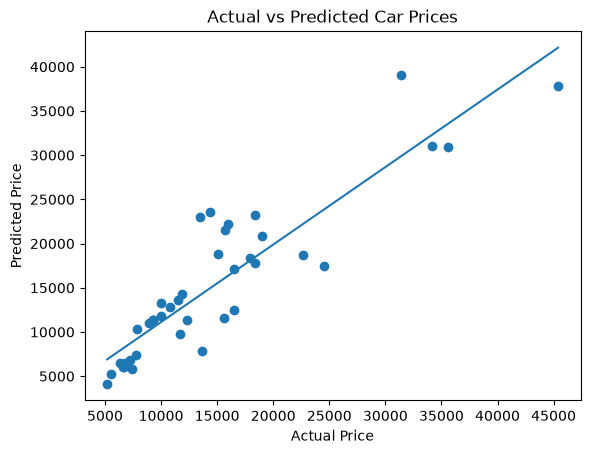

In [30]:
plt.scatter(y_test, y_test_pred)

m, c = np.polyfit(y_test, y_test_pred, 1)

x_line = np.linspace(y_test.min(), y_test.max(), 100)
y_line = m * x_line + c

plt.plot(x_line, y_line)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()

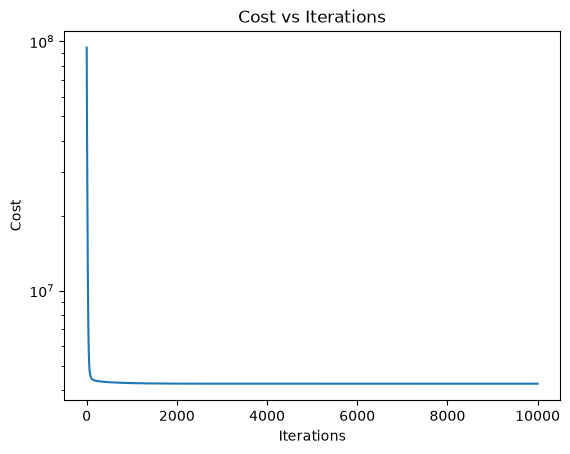

In [31]:
plt.plot(range(1, iterations + 1), cost_history)

plt.yscale("log")

plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost vs Iterations")

plt.show()